# 09 — Classification: Predicting Late Delivery at Checkout

## Business problem
Late delivery is the strongest driver of 1–2 star reviews (Phase 8: 62% vs 9%, adjusted OR 9.5). If risky orders can be identified **when they are placed**, the business can act before the promise is broken, for example by warning the customer, prioritising the shipment or adjusting the promise.

## Definitions
- **Target:** `is_late` = 1 when the order was delivered after the promised date (Gold, day level, D-08).
- **Population:** D-06 eligible orders with items, purchased 2017-01 to 2018-08. This is the same dataset as notebook 08, from the shared module `src/ml/delivery_features.py`.
- **Prediction moment:** checkout. Features are only what is known then: the promise, basket, price, freight, payment, customer and seller location and distance, product weight, volume and category, and purchase date and time.
- **Leakage exclusions** (checked in code): approval, carrier and delivery timestamps, durations, the final status, reviews, and post-purchase flags.

## Validation design
- **Split:** the test set is **2018-05 to 2018-08**, used once. Development is 2017-01 to 2018-04, with tuning on `TimeSeriesSplit` (4 expanding folds).
- **Pipelines and seed:** preprocessing is fitted inside the pipelines, and the seed is fixed at 42.
- **Model selection** uses cross-validated **PR-AUC** (average precision). With about 5–8% positives, PR-AUC measures how well the rare late orders are ranked, while ROC-AUC can look good even when precision is poor. ROC-AUC is reported alongside.
- **Thresholds** are chosen on **out-of-fold development predictions**, never on the test period. Two policies are compared:
  - **capacity:** flag the riskiest 10% of orders, for example a customer-service capacity;
  - **F1-optimal**, as a neutral reference.
- **Class imbalance:** handled with class weights (`balanced`). Resampling isn't used; it would add complexity without a clear benefit for ranking models.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.ml.delivery_features import (CATEGORICAL_INDEX, FEATURES, LEAKAGE_COLUMNS, build_dataset, preprocessor,
                                      temporal_split)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
SEED = 42
FIG = ROOT / "reports" / "machine_learning" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

data = build_dataset()
dev, test = temporal_split(data, "2018-05-01")
X_dev, y_dev, X_test, y_test = dev[FEATURES], dev["is_late"], test[FEATURES], test["is_late"]
cv = TimeSeriesSplit(n_splits=4)

# validation: grain, leakage, temporal order, target = Gold rule (delivered day > promised day)
orders = pd.read_parquet(ROOT / "data" / "processed" / "analytical" / "fact_orders.parquet").set_index("order_id")
o = orders.loc[data["order_id"]]
rule = (o["order_delivered_customer_date"].dt.normalize() > o["order_estimated_delivery_date"].dt.normalize()).astype(int).to_numpy()
assert data["order_id"].is_unique and not (set(FEATURES) & LEAKAGE_COLUMNS)
assert dev["purchase_ts"].max() < test["purchase_ts"].min() and dev["purchase_ts"].is_monotonic_increasing
assert (rule == data["is_late"].to_numpy()).all()
print(f"development {len(dev):,} orders, late rate {y_dev.mean():.2%} | test {len(test):,} orders, late rate {y_test.mean():.2%}")

development 70,851 orders, late rate 7.64% | test 25,352 orders, late rate 4.40%


## 1. Class imbalance and drift

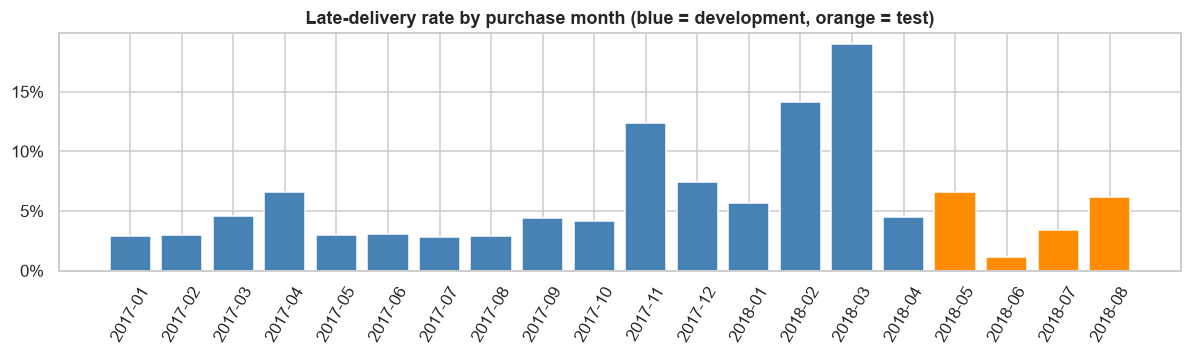

TimeSeriesSplit validation folds - late rate: ['2017-07..2017-10: 3.5%', '2017-10..2017-12: 9.8%', '2017-12..2018-02: 9.0%', '2018-02..2018-04: 12.1%']


In [2]:
monthly = data.groupby(data["purchase_ts"].dt.to_period("M").astype(str)).agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
monthly["set"] = np.where(monthly.index >= "2018-05", "test", "development")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(monthly.index, monthly["late_rate"], color=np.where(monthly["set"] == "test", "darkorange", "steelblue"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.tick_params(axis="x", rotation=60)
ax.set(title="Late-delivery rate by purchase month (blue = development, orange = test)")
plt.tight_layout(); plt.show()
print("TimeSeriesSplit validation folds - late rate:",
      [f"{dev['purchase_ts'].iloc[va[0]]:%Y-%m}..{dev['purchase_ts'].iloc[va[-1]]:%Y-%m}: {y_dev.iloc[va].mean():.1%}" for _, va in cv.split(X_dev)])

**Interpretation.**
- **Imbalance:** about 1 order in 13 is late in development (7.64%) and 1 in 23 in the test period (4.40%).
- **Drift:** the late rate isn't stable. It spikes in Nov 2017 (12%) and Feb–Mar 2018 (14–19%), and falls to 1.2% in Jun 2018.
- **Consequences:**
  - The four cross-validation folds see base rates from 3.5% to 12.1%, so fold-to-fold variation in PR-AUC is expected.
  - Any probability threshold is applied under a **different base rate** in the test period. That makes threshold transfer a real problem (section 4), not a detail.

## 2. Models and tuning (time-series CV on development data, scoring = PR-AUC)

In [3]:
searches = {
    "Logistic regression": GridSearchCV(
        make_pipeline(preprocessor("linear"), LogisticRegression(class_weight="balanced", max_iter=3000)),
        {"logisticregression__C": [0.01, 0.1, 1.0]}, cv=cv, scoring="average_precision", n_jobs=-1),
    "Decision tree": GridSearchCV(
        make_pipeline(preprocessor("onehot"), DecisionTreeClassifier(class_weight="balanced", random_state=SEED)),
        {"decisiontreeclassifier__max_depth": [4, 6, 8], "decisiontreeclassifier__min_samples_leaf": [50, 200]},
        cv=cv, scoring="average_precision", n_jobs=-1),
    "Random forest": GridSearchCV(
        make_pipeline(preprocessor("onehot"), RandomForestClassifier(n_estimators=300, max_features=0.3, class_weight="balanced_subsample",
                                                                     random_state=SEED, n_jobs=-1)),
        {"randomforestclassifier__min_samples_leaf": [10, 50], "randomforestclassifier__max_depth": [12, None]},
        cv=cv, scoring="average_precision"),
    "HistGradientBoosting": RandomizedSearchCV(
        make_pipeline(preprocessor("native"), HistGradientBoostingClassifier(categorical_features=CATEGORICAL_INDEX, random_state=SEED)),
        {"histgradientboostingclassifier__learning_rate": [0.03, 0.06, 0.1], "histgradientboostingclassifier__max_leaf_nodes": [15, 31],
         "histgradientboostingclassifier__min_samples_leaf": [50, 200], "histgradientboostingclassifier__l2_regularization": [0.0, 1.0],
         "histgradientboostingclassifier__class_weight": [None, "balanced"], "histgradientboostingclassifier__max_iter": [300]},
        n_iter=8, cv=cv, scoring="average_precision", random_state=SEED, n_jobs=-1),
}
models = {"Baseline: class prior": DummyClassifier(strategy="prior")}
for name, s in searches.items():
    s.fit(X_dev, y_dev)
    models[name] = s.best_estimator_
    print(f"{name}: CV PR-AUC {s.best_score_:.4f} | {{{', '.join(f'{k.split('__')[1]}: {v}' for k, v in s.best_params_.items())}}}")

Logistic regression: CV PR-AUC 0.1678 | {C: 0.01}


Decision tree: CV PR-AUC 0.1220 | {max_depth: 8, min_samples_leaf: 50}


Random forest: CV PR-AUC 0.1556 | {max_depth: 12, min_samples_leaf: 50}


HistGradientBoosting: CV PR-AUC 0.1568 | {min_samples_leaf: 50, max_leaf_nodes: 15, max_iter: 300, learning_rate: 0.03, l2_regularization: 1.0, class_weight: None}


In [4]:
rows, proba = [], {}
for name, model in models.items():
    cvr = cross_validate(model, X_dev, y_dev, cv=cv, scoring={"pr": "average_precision", "roc": "roc_auc"}, return_train_score=True)
    model.fit(X_dev, y_dev)
    proba[name] = model.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "train PR-AUC": cvr["train_pr"].mean(), "CV PR-AUC": cvr["test_pr"].mean(), "CV PR-AUC sd": cvr["test_pr"].std(),
                 "CV ROC-AUC": cvr["test_roc"].mean(), "test PR-AUC": average_precision_score(y_test, proba[name]),
                 "test ROC-AUC": roc_auc_score(y_test, proba[name])})
results = pd.DataFrame(rows).set_index("model")
display(results)
BEST = results.drop(index="Baseline: class prior")["CV PR-AUC"].idxmax()          # selected on CV, not on test
print(f"model selected on cross-validation: {BEST} | test late rate (= PR-AUC of a random ranking) {y_test.mean():.4f}")

,train PR-AUC,CV PR-AUC,CV PR-AUC sd,CV ROC-AUC,test PR-AUC,test ROC-AUC
model,,,,,,
Baseline: class prior,0.0492,0.0860,0.0319,0.5000,0.0440,0.5000
Logistic regression,0.1188,0.1678,0.0776,0.6785,0.0883,0.7032
Decision tree,0.1854,0.1220,0.0452,0.5955,0.0650,0.6292
Random forest,0.3698,0.1556,0.0625,0.6640,0.0756,0.6778
HistGradientBoosting,0.3371,0.1568,0.0794,0.6569,0.1030,0.7269


model selected on cross-validation: Logistic regression | test late rate (= PR-AUC of a random ranking) 0.0440


**Interpretation.**
- **Selection:** **logistic regression** has the best cross-validated PR-AUC (0.168, about 2× the prior baseline of 0.086) and is selected. The ensembles (random forest 0.156, HistGradientBoosting 0.157) are within one cross-validation standard deviation (about 0.08), so **the models are statistically indistinguishable on development data**.
- **Test period:** HistGradientBoosting ranks best (PR-AUC 0.103, ROC-AUC 0.73 vs logistic regression's 0.088 and 0.70). Choosing it now would be test-set selection, so logistic regression remains the selected model. The gap is reported, not acted on.
- **Overfitting:** the random forest and boosting models reach train PR-AUC 0.37 and 0.34, but only about 0.16 on later folds. The decision tree generalises worst (CV 0.12). The regularised linear model (C = 0.01) loses the least between training and validation.
- **Overall:** every trained model beats the baseline, with **PR-AUC about 2× the base rate and ROC-AUC 0.66–0.73.** This is a weak but real signal. Most lateness isn't determined by what's known at checkout: carrier capacity, seasonal peaks and strikes happen afterwards.

## 3. Threshold selection on out-of-fold development predictions
The selected model is refitted on each time-series fold's training part and scores that fold's validation months. These **out-of-fold** scores (2017-07 to 2018-04) are honest estimates of future performance, and they are used to set the thresholds. The test period is not used.

In [5]:
oof_idx, oof = [], []
for tr, va in cv.split(X_dev):
    m = clone(models[BEST]).fit(X_dev.iloc[tr], y_dev.iloc[tr])
    oof_idx.append(va); oof.append(m.predict_proba(X_dev.iloc[va])[:, 1])
oof_idx, oof = np.concatenate(oof_idx), np.concatenate(oof)
y_oof = y_dev.iloc[oof_idx].to_numpy()
p, r, t = precision_recall_curve(y_oof, oof)
f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
thresholds = {"capacity: top 10% of orders": float(np.quantile(oof, 0.90)), "F1-optimal": float(t[np.argmax(f1)])}
tab = pd.DataFrame({name: {"threshold": th, "flagged share": (oof >= th).mean(), "precision": precision_score(y_oof, oof >= th),
                           "recall": recall_score(y_oof, oof >= th), "F1": f1_score(y_oof, oof >= th)} for name, th in thresholds.items()}).T
print(f"out-of-fold development predictions: {len(oof):,} orders, late rate {y_oof.mean():.2%}, PR-AUC {average_precision_score(y_oof, oof):.4f}")
display(tab)

out-of-fold development predictions: 56,680 orders, late rate 8.60%, PR-AUC 0.1851


,threshold,flagged share,precision,recall,F1
capacity: top 10% of orders,0.5718,0.1000,0.2299,0.2673,0.2472
F1-optimal,0.4885,0.1984,0.1831,0.4224,0.2555


**Interpretation (out-of-fold development predictions, 56,680 orders, late rate 8.6%):**
- **Capacity policy:** flagging the riskiest **10%** of orders catches 26.7% of late orders, with precision 23.0% (2.7× the base rate).
- **F1-optimal threshold:** flags 19.8% of orders, with recall 42.2% and precision 18.3%.

Both thresholds are fixed here, before the test period is touched. The capacity policy matches how the alerts would be used, for example a team able to handle about 10% of orders proactively.

## 4. Test-period evaluation (selected model, thresholds fixed in advance)

Logistic regression on 2018-05..2018-08: PR-AUC 0.0883, ROC-AUC 0.7032, late rate 4.40%


,flagged share,precision,recall,F1,lift (precision / late rate)
capacity: top 10% of orders,0.2769,0.0815,0.5130,0.1406,1.8527
F1-optimal,0.4539,0.0727,0.7507,0.1326,1.6537
capacity: top 10% of test orders (re-ranked),0.1000,0.1033,0.2350,0.1435,2.3490


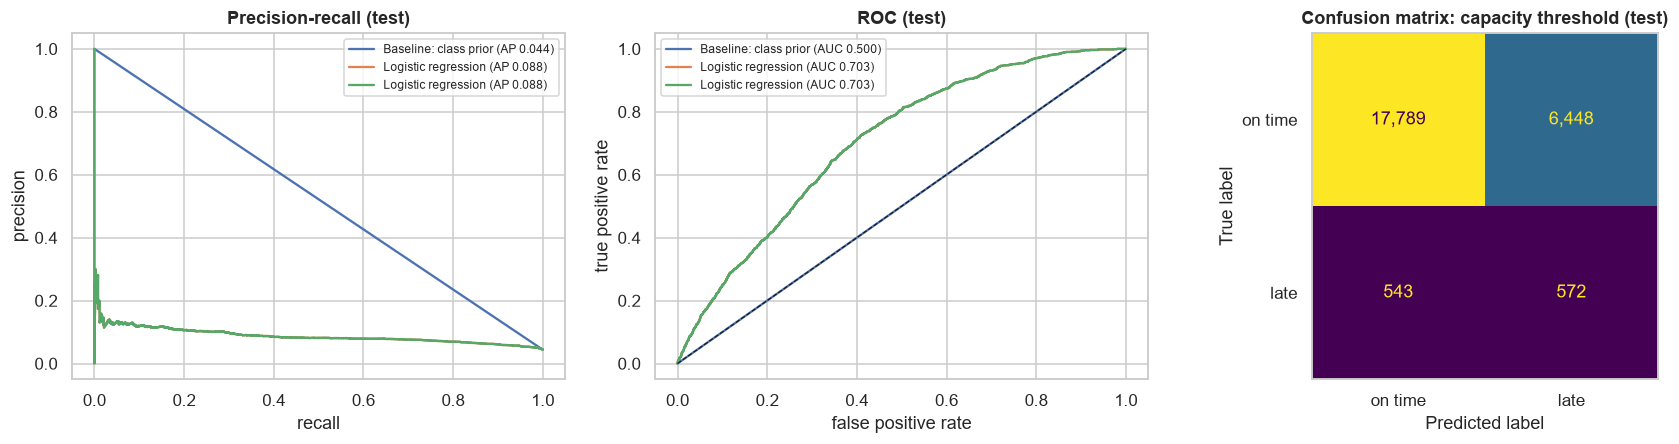

In [6]:
s = proba[BEST]
def at(th):
    pred = s >= th
    return {"flagged share": pred.mean(), "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "lift (precision / late rate)": precision_score(y_test, pred) / y_test.mean()}
test_tab = pd.DataFrame({name: at(th) for name, th in thresholds.items()}).T
# operational variant of the capacity policy: flag the top 10% of the period's own orders (a ranking, no labels needed)
rank_th = np.quantile(s, 0.90)
test_tab.loc["capacity: top 10% of test orders (re-ranked)"] = at(rank_th)
print(f"{BEST} on 2018-05..2018-08: PR-AUC {average_precision_score(y_test, s):.4f}, ROC-AUC {roc_auc_score(y_test, s):.4f}, late rate {y_test.mean():.2%}")
display(test_tab)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name in ("Baseline: class prior", "Logistic regression", BEST):
    pr_p, pr_r, _ = precision_recall_curve(y_test, proba[name]); fpr, tpr, _ = roc_curve(y_test, proba[name])
    ax[0].plot(pr_r, pr_p, label=f"{name} (AP {average_precision_score(y_test, proba[name]):.3f})")
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba[name]):.3f})")
ax[0].set(title="Precision-recall (test)", xlabel="recall", ylabel="precision"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set(title="ROC (test)", xlabel="false positive rate", ylabel="true positive rate"); ax[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_test, s >= thresholds["capacity: top 10% of orders"]), display_labels=["on time", "late"]).plot(
    ax=ax[2], colorbar=False, values_format=",")
ax[2].set_title("Confusion matrix: capacity threshold (test)"); ax[2].grid(False)
plt.tight_layout(); plt.savefig(FIG / "classification_curves.png", bbox_inches="tight"); plt.show()

**Interpretation (test period 2018-05 to 2018-08, logistic regression):**
- **Thresholds don't transfer under drift.** The probability threshold fixed in development to flag 10% of orders **flags 27.7% of test orders**, and the F1 threshold flags 45%.

  This happens because promises changed: the median promise was 22 days in May 2018, 28 in June, 20 in July and **14 in August**, against 23–28 days for most of 2017. The promise is the model's strongest risk signal, so shorter promises raise the scores, while the actual late rate in the test period was low (4.4%). The monthly flagged share follows the promise: 12% in June, 42% in August.

  At the fixed capacity threshold the model catches 51% of late orders, but precision is only 8.2% (1.85× the base rate).
- **Ranking does transfer.** Flagging the **top 10% of the period's own orders by score** needs no labels and is operationally realistic (for example, today's riskiest 10%). It gives precision 10.3%, recall 23.5% and **lift 2.35×**.

**Practical reading:**
- Use the model as a **ranking** with a capacity rule, not as a calibrated probability with a fixed cut-off.
- Re-rank or recalibrate whenever promises or volumes change.
- The confusion matrix shows the cost of the weak signal: most flagged orders arrive on time, so any action on a flag must be cheap (for example a proactive message, not a re-routed shipment).

## 5. Error analysis (test period, capacity threshold)

In [7]:
th = thresholds["capacity: top 10% of orders"]
ea = test.assign(score=s, flagged=s >= th,
                 days_late=orders.loc[test["order_id"], "delivery_vs_estimate_days"].to_numpy(),   # analysis only, never a feature
                 region=test["customer_state"].map({**dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Norte"),
                                                    **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
                                                    **dict.fromkeys(["DF", "GO", "MT", "MS"], "Centro-Oeste"),
                                                    **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"), **dict.fromkeys(["PR", "RS", "SC"], "Sul")}))
def grp(g):
    late = g["is_late"] == 1
    return pd.Series({"orders": len(g), "late rate": late.mean(), "flagged share": g["flagged"].mean(),
                      "recall": g.loc[late, "flagged"].mean() if late.any() else np.nan,
                      "precision": g.loc[g["flagged"], "is_late"].mean() if g["flagged"].any() else np.nan})
display(ea.groupby(ea["purchase_ts"].dt.to_period("M").astype(str)).apply(grp, include_groups=False))
display(ea.groupby("region").apply(grp, include_groups=False).sort_values("orders", ascending=False))
late = ea[ea["is_late"] == 1].copy()
late["severity"] = pd.cut(late["days_late"], [0, 3, 7, 14, 1000], labels=["1-3 days", "4-7 days", "8-14 days", ">14 days"])
display(late.groupby("severity", observed=True)["flagged"].agg(late_orders="size", recall="mean"))
cmp = ea[ea["is_late"] == 1].groupby("flagged")[["promised_days", "distance_km", "items_freight_total", "total_weight_kg"]].median()
cmp.index = ["missed late orders (FN)", "caught late orders (TP)"]
display(cmp)

,orders,late rate,flagged share,recall,precision
purchase_ts,,,,,
2018-05,"6,749.0000",0.0656,0.2371,0.5395,0.1494
2018-06,"6,096.0000",0.0116,0.1194,0.3803,0.0371
2018-07,"6,156.0000",0.0338,0.3283,0.5481,0.0564
2018-08,"6,351.0000",0.0619,0.4206,0.4885,0.0719


,orders,late rate,flagged share,recall,precision
region,,,,,
Sudeste,"17,980.0000",0.0439,0.2007,0.4215,0.0923
Sul,"3,337.0000",0.0267,0.3135,0.3483,0.0296
Nordeste,"2,191.0000",0.0726,0.7202,0.8805,0.0887
Centro-Oeste,"1,452.0000",0.0427,0.4146,0.8710,0.0897
Norte,392.0000,0.0383,0.4719,0.9333,0.0757


,late_orders,recall
severity,,
1-3 days,452,0.4690
4-7 days,358,0.5307
8-14 days,208,0.5721
>14 days,97,0.5258


,promised_days,distance_km,items_freight_total,total_weight_kg
missed late orders (FN),14.0000,124.9766,13.7200,0.6250
caught late orders (TP),18.0000,667.6921,19.5000,0.7000


**Interpretation:**
- **By month:** recall stays between 38% and 55%, but precision follows the base rate (3.7% in June when only 1.2% are late; 15% in May). The flagged share drifts with the promise length (12% to 42%).
- **By region:** the model flags most remote orders (72% in Nordeste, about 41–47% in Centro-Oeste and Norte), so it catches 87–93% of their late orders. In Sudeste, where most orders are, it flags 20% and catches 42%. In effect the model learned "far away = risky", which is true but coarse.
- **By severity:** recall barely improves with how late an order is (47% at 1–3 days late, 52–57% at 4+ days). Severe delays aren't more predictable at checkout.
- **Missed late orders** look like ordinary low-risk orders: a median distance of 125 km against 668 km for caught ones, and shorter promises (14 vs 18 days). These are **local orders that went wrong afterwards**, an operational failure that no checkout feature can reveal.

**Business meaning:** reducing lateness further needs **post-checkout signals**: approval delays, carrier hand-over times and seller dispatch behaviour. A model updated at those later moments would probably do much better, but it would be a different prediction problem with a later prediction moment. It would need its own leakage rules.

## 6. Feature importance (permutation, test period)
This is the drop in test PR-AUC when one feature is shuffled. It is model-agnostic and computed on held-out data, and it shows **what the model uses, not what causes lateness**. SHAP explanations belong to the explainability phase.

,PR-AUC drop,sd
promised_days,0.0393,0.0011
seller_lat,0.0069,0.0023
distance_km,0.0044,0.0018
seller_state,0.0028,0.0011
customer_state,0.0028,0.0011
purchase_month,0.0018,0.0002
distinct_sellers,0.0012,0.0006
item_count,0.0012,0.0003
payment_type,0.0010,0.0004
customer_lng,0.0006,0.0002


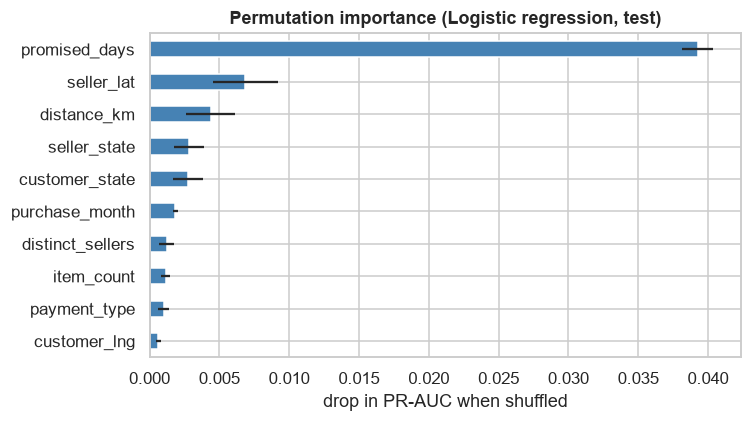

In [8]:
pi = permutation_importance(models[BEST], X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"PR-AUC drop": pi.importances_mean, "sd": pi.importances_std}, index=FEATURES).sort_values("PR-AUC drop", ascending=False)
display(imp.head(10))
fig, ax = plt.subplots(figsize=(7, 4))
imp.head(10)["PR-AUC drop"][::-1].plot.barh(xerr=imp.head(10)["sd"][::-1], ax=ax, color="steelblue")
ax.set(title=f"Permutation importance ({BEST}, test)", xlabel="drop in PR-AUC when shuffled")
plt.tight_layout(); plt.savefig(FIG / "classification_importance.png", bbox_inches="tight"); plt.show()

**Interpretation.**
- **The promised delivery time dominates** (PR-AUC drop 0.039, an order of magnitude above any other feature). Shorter promises carry more risk, which fits the 2018 drift.
- **Next come geography:** seller location (seller latitude 0.007), customer–seller distance (0.004), and seller and customer state.
- **Basket, payment and timing features add little.**

Importance means "the model uses it", not "it causes lateness". For example, the promise is itself set by Olist using route information, so its importance partly reflects geography already.

## 7. Relation to Phase 9 (unsupervised segmentation)
Phase 9 already segmented customers with RFM rules and K-Means, so it isn't repeated here. The difference matters:
- **Segmentation (unsupervised)** has **no target**. It groups customers by similarity in behaviour (recency, value, payment, freight), and its quality is judged by cohesion, stability and business usefulness.
- **The models in notebooks 08–09 (supervised)** learn a mapping from features to a **known outcome** (delivery days, late or not) and are judged by error on unseen, later data.

The two can be combined, for example by monitoring late-delivery risk by customer segment, but neither replaces the other.

## 8. Summary

| Item | Result |
|---|---|
| Target / moment | late delivery (Gold `is_late`) predicted at checkout; leakage-checked features |
| Validation | temporal test 2018-05 to 2018-08 (25,352 orders, 4.40% late); `TimeSeriesSplit` CV on 2017-01 to 2018-04 |
| Selected model (by CV PR-AUC) | logistic regression (balanced class weights, C = 0.01): CV PR-AUC 0.168 vs 0.086 baseline |
| Test | PR-AUC 0.088 (2.0× base rate), ROC-AUC 0.70; HistGradientBoosting 0.103 / 0.73, not selected (no test-set selection) |
| Operating point | top 10% of orders re-ranked per period: precision 10.3%, recall 23.5%, lift 2.35× |
| Key finding | late delivery is only weakly predictable at checkout. The promise length and geography carry most of the signal; most lateness arises after checkout |

**Business implications:**
1. Use the model for **low-cost, proactive actions on a risk ranking**, such as customer messaging or extra monitoring of the riskiest orders, not for expensive interventions.
2. Don't apply a fixed probability threshold after changes to promises or volume. **Re-rank per period, or recalibrate.**
3. The larger lever is **later signals** (approval, carrier hand-over, seller dispatch) and the promise itself. Notebook 08's quantile model shows how promises could be set more accurately.

**Limitations:**
- **Population:** orders delivered with a date (D-06). Undelivered and canceled orders have no label.
- **Probabilities aren't calibrated:** the class weights shift them, so they are scores, not probabilities.
- **Data and time span:** the features exclude seller history (time-aware seller statistics would be a leakage-safe extension), and the evaluation period has strong drift.